<a href="https://colab.research.google.com/github/tommihab/CNN-LSTM-discharge-forecasting-of-the-Darling-River-/blob/main/Google%20Colab%20Jupyter%20Notebooks/CNN_LSTM_Bourke.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# This python notebook contains the code for the study "Dual-Input CNN-LSTM for river discharge forecasting of the Darling River, Australia, using gridded Hydro-Meteorological data"

In [ ]:
# Import packages

import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    TimeDistributed,
    Conv2D,
    MaxPooling2D,
    Flatten,
    LSTM,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.20.0


In [ ]:
# Set random seed

SEED = 100

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"Random seed set to {SEED}.")

try:
    tf.keras.utils.set_random_seed(SEED)
    tf.config.experimental.enable_op_determinism()
    print("Deterministic execution enabled.")
except Exception as e:
    print("Note:", e)

SEED wurde auf 100 gesetzt.
Deterministische Ausführung aktiviert.


In [ ]:
# 1) Mount Google Drive

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Define file paths

# Folder path pointing to your Google Drive directory
folder_path = "/content/drive/MyDrive/Raster_Data_Bourke_Discharge_Forecasting_CNN-LSTM/processed_input_data"

# Define file names here
discharge_csv_name = "discharge_aligned.csv"
precip_nc_name = "precip_aligned.nc"
et_nc_name = "et_aligned.nc"
soil_nc_name = "sm_aligned.nc"

# Build full file paths
discharge_csv_path = os.path.join(folder_path, discharge_csv_name)
precip_nc_path = os.path.join(folder_path, precip_nc_name)
et_nc_path = os.path.join(folder_path, et_nc_name)
soil_nc_path = os.path.join(folder_path, soil_nc_name)

print("Discharge CSV:", discharge_csv_path)
print("Precipitation NC:", precip_nc_path)
print("Evapotranspiration NC:", et_nc_path)
print("Soil moisture NC:", soil_nc_path)

Discharge CSV: /content/drive/MyDrive/Raster_Data_Bourke_Discharge_Forecasting_CNN-LSTM/processed_input_data/discharge_aligned.csv
Precipitation NC: /content/drive/MyDrive/Raster_Data_Bourke_Discharge_Forecasting_CNN-LSTM/processed_input_data/precip_aligned.nc
Evapotranspiration NC: /content/drive/MyDrive/Raster_Data_Bourke_Discharge_Forecasting_CNN-LSTM/processed_input_data/et_aligned.nc
Soil moisture NC: /content/drive/MyDrive/Raster_Data_Bourke_Discharge_Forecasting_CNN-LSTM/processed_input_data/sm_aligned.nc


In [ ]:
# Load data

discharge_df = pd.read_csv(discharge_csv_path)

precip_ds = xr.open_dataset(precip_nc_path)
et_ds = xr.open_dataset(et_nc_path)
soil_ds = xr.open_dataset(soil_nc_path)

print("Files loaded successfully.")

Files loaded successfully.


In [ ]:
# Inspect loaded data

print("\n--- Discharge data ---")
display(discharge_df.head())
discharge_df.info()

print("\n--- Precipitation dataset ---")
print(precip_ds)

print("\n--- Evapotranspiration dataset ---")
print(et_ds)

print("\n--- Soil moisture dataset ---")
print(soil_ds)


--- Discharge CSV ---


,Timestamp,Value
0,1972-06-21,5.791
1,1972-06-22,5.858
2,1972-06-23,5.611
3,1972-06-24,5.811
4,1972-06-25,6.024


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18330 entries, 0 to 18329
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Timestamp  18330 non-null  object 
 1   Value      18330 non-null  float64
dtypes: float64(1), object(1)
memory usage: 286.5+ KB
None

--- Precipitation dataset ---
<xarray.Dataset> Size: 2GB
Dimensions:   (time: 18330, y: 181, x: 134)
Coordinates:
  * time      (time) datetime64[ns] 147kB 1972-06-21 1972-06-22 ... 2025-12-31
  * y         (y) float64 1kB -24.9 -24.95 -25.0 -25.05 ... -33.8 -33.85 -33.9
  * x         (x) float64 1kB 145.8 145.8 145.9 145.9 ... 152.3 152.4 152.4
Data variables:
    rain_day  (time, y, x) float32 2GB ...

--- Evapotranspiration dataset ---
<xarray.Dataset> Size: 2GB
Dimensions:             (time: 18330, y: 181, x: 134)
Coordinates:
  * time                (time) datetime64[ns] 147kB 1972-06-21 ... 2025-12-31
  * y                   (y) float64 1kB -24.9 -24.95 -25.

In [ ]:
# Detect gaps in the discharge time series

discharge_df["Timestamp"] = pd.to_datetime(discharge_df["Timestamp"])
discharge_df = discharge_df.sort_values("Timestamp").reset_index(drop=True)

discharge_df["time_diff_days"] = discharge_df["Timestamp"].diff().dt.days
gap_rows = discharge_df[discharge_df["time_diff_days"] > 1].copy()

print("Detected gaps:")
for idx, row in gap_rows.iterrows():
    gap_start = discharge_df.loc[idx - 1, "Timestamp"]
    gap_end = row["Timestamp"]
    missing_days = int(row["time_diff_days"] - 1)

    print(
        f"Gap from {gap_start.date()} to {gap_end.date()} | "
        f"Missing days: {missing_days}"
    )

Detected gaps:
Gap from 1985-12-31 to 1987-01-01 | Missing days: 365
Gap from 2012-09-09 to 2015-01-15 | Missing days: 857


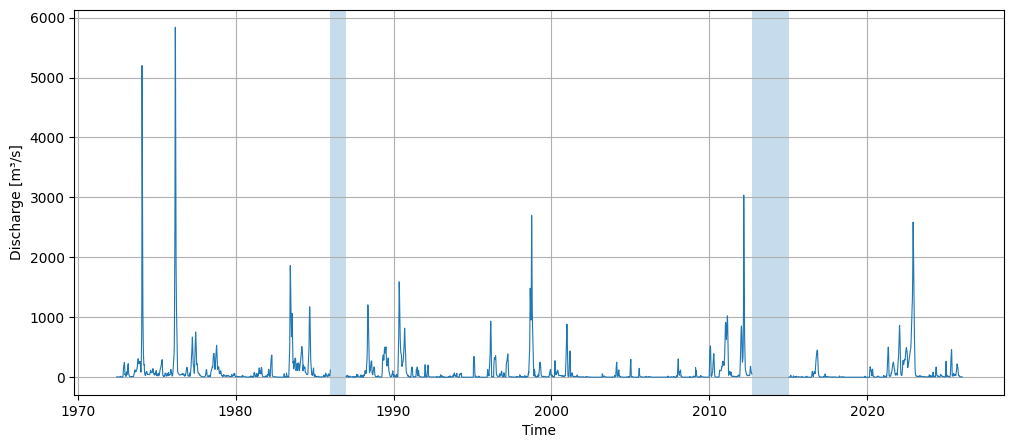

In [ ]:
# Plot discharge without connecting gaps

full_range = pd.date_range(
    discharge_df["Timestamp"].min(),
    discharge_df["Timestamp"].max(),
    freq="D"
)

discharge_full = (
    discharge_df.set_index("Timestamp")[["Value"]]
    .reindex(full_range)
    .rename_axis("Timestamp")
    .reset_index()
)

plt.figure(figsize=(12, 5))
plt.plot(discharge_full["Timestamp"], discharge_full["Value"], linewidth=0.8)

# Shade missing periods
for idx, row in gap_rows.iterrows():
    gap_start = discharge_df.loc[idx - 1, "Timestamp"]
    gap_end = row["Timestamp"]
    plt.axvspan(gap_start, gap_end, alpha=0.25)

plt.xlabel("Time")
plt.ylabel("Discharge [m³/s]")
plt.grid(True)
plt.show()

In [ ]:
# Split data into training, validation, and test sets

if len(gap_rows) < 2:
    raise ValueError("Fewer than two gaps were found in the discharge time series.")

# Use the second gap as the start of the test period
second_gap_idx = gap_rows.index[1]
test_start_date = discharge_df.loc[second_gap_idx, "Timestamp"]

train_val_df = discharge_df[
    discharge_df["Timestamp"] < test_start_date
].copy()

test_df = discharge_df[
    discharge_df["Timestamp"] >= test_start_date
].copy()

# Use the last 15% of the pre-test period for validation
val_fraction = 0.15
val_size = int(round(len(train_val_df) * val_fraction))

train_df = train_val_df.iloc[:-val_size].copy()
val_df = train_val_df.iloc[-val_size:].copy()

# Remove the helper column
train_df = train_df.drop(columns=["time_diff_days"])
val_df = val_df.drop(columns=["time_diff_days"])
test_df = test_df.drop(columns=["time_diff_days"])
train_val_df = train_val_df.drop(columns=["time_diff_days"])
discharge_df = discharge_df.drop(columns=["time_diff_days"])

# Show split summary
total_n = len(discharge_df)
train_n = len(train_df)
val_n = len(val_df)
test_n = len(test_df)

print("Split summary:")
print(f"Training:   {train_n} samples ({train_n / total_n * 100:.2f}%)")
print(f"Validation: {val_n} samples ({val_n / total_n * 100:.2f}%)")
print(f"Test:       {test_n} samples ({test_n / total_n * 100:.2f}%)")

print("\nDate ranges:")
print(f"Training:   {train_df['Timestamp'].min().date()} -> {train_df['Timestamp'].max().date()}")
print(f"Validation: {val_df['Timestamp'].min().date()} -> {val_df['Timestamp'].max().date()}")
print(f"Test:       {test_df['Timestamp'].min().date()} -> {test_df['Timestamp'].max().date()}")

Detected gaps:
Gap 1: 1985-12-31 -> 1987-01-01 | Missing days: 365
Gap 2: 2012-09-09 -> 2015-01-15 | Missing days: 857

Split summary:
Total samples:      18330
Training samples:   12177 (66.43%)
Validation samples: 2149 (11.72%)
Test samples:       4004 (21.84%)

Date ranges:
Training:   1972-06-21 -> 2006-10-22
Validation: 2006-10-23 -> 2012-09-09
Test:       2015-01-15 -> 2025-12-31

Boundary dates:
Validation starts at: 2006-10-23
Test starts at:       2015-01-15

Training head:


,Timestamp,Value
0,1972-06-21,5.791
1,1972-06-22,5.858
2,1972-06-23,5.611
3,1972-06-24,5.811
4,1972-06-25,6.024



Validation head:


,Timestamp,Value
12177,2006-10-23,0.0
12178,2006-10-24,0.0
12179,2006-10-25,0.0
12180,2006-10-26,0.0
12181,2006-10-27,0.0



Test head:


,Timestamp,Value
14326,2015-01-15,0.0
14327,2015-01-16,0.0
14328,2015-01-17,0.0
14329,2015-01-18,0.0
14330,2015-01-19,0.0


In [ ]:
# Split raster datasets using the discharge split periods

train_start = train_df["Timestamp"].min()
train_end = train_df["Timestamp"].max()

val_start = val_df["Timestamp"].min()
val_end = val_df["Timestamp"].max()

test_start = test_df["Timestamp"].min()
test_end = test_df["Timestamp"].max()

# Ensure raster time coordinates use datetime
precip_ds["time"] = pd.to_datetime(precip_ds["time"].values)
et_ds["time"] = pd.to_datetime(et_ds["time"].values)
soil_ds["time"] = pd.to_datetime(soil_ds["time"].values)

# Split raster datasets
precip_train = precip_ds.sel(time=slice(train_start, train_end))
precip_val = precip_ds.sel(time=slice(val_start, val_end))
precip_test = precip_ds.sel(time=slice(test_start, test_end))

et_train = et_ds.sel(time=slice(train_start, train_end))
et_val = et_ds.sel(time=slice(val_start, val_end))
et_test = et_ds.sel(time=slice(test_start, test_end))

soil_train = soil_ds.sel(time=slice(train_start, train_end))
soil_val = soil_ds.sel(time=slice(val_start, val_end))
soil_test = soil_ds.sel(time=slice(test_start, test_end))

# Check that discharge and raster lengths match
print("Time consistency check:")

print("\nTraining:")
print("Discharge:", len(train_df))
print("Precipitation:", precip_train.sizes["time"])
print("Evapotranspiration:", et_train.sizes["time"])
print("Soil moisture:", soil_train.sizes["time"])

print("\nValidation:")
print("Discharge:", len(val_df))
print("Precipitation:", precip_val.sizes["time"])
print("Evapotranspiration:", et_val.sizes["time"])
print("Soil moisture:", soil_val.sizes["time"])

print("\nTest:")
print("Discharge:", len(test_df))
print("Precipitation:", precip_test.sizes["time"])
print("Evapotranspiration:", et_test.sizes["time"])
print("Soil moisture:", soil_test.sizes["time"])

Detected gaps:
Gap 1: 1985-12-31 -> 1987-01-01 | Missing days: 365
Gap 2: 2012-09-09 -> 2015-01-15 | Missing days: 857

Split summary:
Total samples:      18330
Training samples:   12177 (66.43%)
Validation samples: 2149 (11.72%)
Test samples:       4004 (21.84%)

Date ranges:
Training:   1972-06-21 -> 2006-10-22
Validation: 2006-10-23 -> 2012-09-09
Test:       2015-01-15 -> 2025-12-31

Raster split overview:
Precipitation:
  Train: FrozenMappingWarningOnValuesAccess({'time': 12177, 'y': 181, 'x': 134})
  Val:   FrozenMappingWarningOnValuesAccess({'time': 2149, 'y': 181, 'x': 134})
  Test:  FrozenMappingWarningOnValuesAccess({'time': 4004, 'y': 181, 'x': 134})
Evapotranspiration:
  Train: FrozenMappingWarningOnValuesAccess({'time': 12177, 'y': 181, 'x': 134})
  Val:   FrozenMappingWarningOnValuesAccess({'time': 2149, 'y': 181, 'x': 134})
  Test:  FrozenMappingWarningOnValuesAccess({'time': 4004, 'y': 181, 'x': 134})
Soil moisture:
  Train: FrozenMappingWarningOnValuesAccess({'time': 12

In [ ]:
# Normalize discharge using training data

discharge_train_min = train_df["Value"].min()
discharge_train_max = train_df["Value"].max()

if discharge_train_max == discharge_train_min:
    raise ValueError("Discharge training minimum and maximum are identical.")

train_df["Value_norm"] = (
    (train_df["Value"] - discharge_train_min)
    / (discharge_train_max - discharge_train_min)
)

val_df["Value_norm"] = (
    (val_df["Value"] - discharge_train_min)
    / (discharge_train_max - discharge_train_min)
)

test_df["Value_norm"] = (
    (test_df["Value"] - discharge_train_min)
    / (discharge_train_max - discharge_train_min)
)

print("Discharge scaling parameters:")
print(f"Training min: {discharge_train_min:.6f}")
print(f"Training max: {discharge_train_max:.6f}")

print("\nNormalized value ranges:")
print(f"Training:   {train_df['Value_norm'].min():.6f} to {train_df['Value_norm'].max():.6f}")
print(f"Validation: {val_df['Value_norm'].min():.6f} to {val_df['Value_norm'].max():.6f}")
print(f"Test:       {test_df['Value_norm'].min():.6f} to {test_df['Value_norm'].max():.6f}")

Discharge Min-Max parameters:
Train min: 0.000000
Train max: 5838.860000

Discharge normalization check:
Train min: 0.000000
Train max: 1.000000
Validation min: 0.000000
Validation max: 0.520481
Test min: 0.000000
Test max: 0.442993


In [ ]:
# Normalize precipitation using log1p and Min-Max scaling

precip_var_name = "rain_day"

precip_train_raw = precip_train[precip_var_name]
precip_val_raw = precip_val[precip_var_name]
precip_test_raw = precip_test[precip_var_name]

# Apply log1p while preserving NoData pixels
precip_train_log = xr.where(
    np.isnan(precip_train_raw), np.nan, np.log1p(precip_train_raw)
)
precip_val_log = xr.where(
    np.isnan(precip_val_raw), np.nan, np.log1p(precip_val_raw)
)
precip_test_log = xr.where(
    np.isnan(precip_test_raw), np.nan, np.log1p(precip_test_raw)
)

# Calculate scaling parameters from training data only
precip_train_min = float(precip_train_log.min(skipna=True).values)
precip_train_max = float(precip_train_log.max(skipna=True).values)

if precip_train_max == precip_train_min:
    raise ValueError(
        "Valid precipitation training minimum and maximum are identical."
    )

# Min-Max scaling
precip_train_norm = (
    (precip_train_log - precip_train_min)
    / (precip_train_max - precip_train_min)
)
precip_val_norm = (
    (precip_val_log - precip_train_min)
    / (precip_train_max - precip_train_min)
)
precip_test_norm = (
    (precip_test_log - precip_train_min)
    / (precip_train_max - precip_train_min)
)

# Use -1 for NoData pixels
precip_train_norm = precip_train_norm.fillna(-1).astype("float32")
precip_val_norm = precip_val_norm.fillna(-1).astype("float32")
precip_test_norm = precip_test_norm.fillna(-1).astype("float32")

print("Precipitation scaling parameters:")
print(f"Training min: {precip_train_min:.6f}")
print(f"Training max: {precip_train_max:.6f}")

print("\nNaN count after preprocessing:")
print("Training:", np.isnan(precip_train_norm.values).sum())
print("Validation:", np.isnan(precip_val_norm.values).sum())
print("Test:", np.isnan(precip_test_norm.values).sum())

print("\nNormalized value ranges:")
print(
    f"Training:   {precip_train_norm.values.min():.6f} "
    f"to {precip_train_norm.values.max():.6f}"
)
print(
    f"Validation: {precip_val_norm.values.min():.6f} "
    f"to {precip_val_norm.values.max():.6f}"
)
print(
    f"Test:       {precip_test_norm.values.min():.6f} "
    f"to {precip_test_norm.values.max():.6f}"
)

Precipitation scaling parameters:
Train min: 0.000000
Train max: 5.670226

NaN check after precipitation preprocessing:
Train: 0
Val:   0
Test:  0

Precipitation value range check:
Train min: -1.0
Train max: 1.0
Val min:   -1.0
Val max:   0.9546329975128174
Test min:  -1.0
Test max:  0.9362524151802063


In [ ]:
# Normalise evapotranspiration using Min-Max scaling

et_var_name = "evapotranspiration"

et_train_raw = et_train[et_var_name]
et_val_raw = et_val[et_var_name]
et_test_raw = et_test[et_var_name]

# Calculate scaling parameters from training data only
et_train_min = float(et_train_raw.min(skipna=True).values)
et_train_max = float(et_train_raw.max(skipna=True).values)

if et_train_max == et_train_min:
    raise ValueError(
        "Valid ET training minimum and maximum are identical."
    )

# Min-Max scaling
et_train_norm = (
    (et_train_raw - et_train_min)
    / (et_train_max - et_train_min)
)
et_val_norm = (
    (et_val_raw - et_train_min)
    / (et_train_max - et_train_min)
)
et_test_norm = (
    (et_test_raw - et_train_min)
    / (et_train_max - et_train_min)
)

# Use -1 for NoData pixels
et_train_norm = et_train_norm.fillna(-1).astype("float32")
et_val_norm = et_val_norm.fillna(-1).astype("float32")
et_test_norm = et_test_norm.fillna(-1).astype("float32")

print("ET scaling parameters:")
print(f"Training min: {et_train_min:.6f}")
print(f"Training max: {et_train_max:.6f}")

print("\nNaN count after preprocessing:")
print("Training:", np.isnan(et_train_norm.values).sum())
print("Validation:", np.isnan(et_val_norm.values).sum())
print("Test:", np.isnan(et_test_norm.values).sum())

print("\nNormalised value ranges:")
print(
    f"Training:   {et_train_norm.values.min():.6f} "
    f"to {et_train_norm.values.max():.6f}"
)
print(
    f"Validation: {et_val_norm.values.min():.6f} "
    f"to {et_val_norm.values.max():.6f}"
)
print(
    f"Test:       {et_test_norm.values.min():.6f} "
    f"to {et_test_norm.values.max():.6f}"
)

ET scaling parameters:
Train min: 0.000000
Train max: 21.568546

NaN check after ET preprocessing:
Train: 0
Val:   0
Test:  0

ET value range check:
Train min: -1.0
Train max: 1.0
Val min:   -1.0
Val max:   0.6115401983261108
Test min:  -1.0
Test max:  0.7401981949806213


In [ ]:
# Normalise soil moisture using Min-Max scaling

soil_var_name = "soil_moisture"

soil_train_raw = soil_train[soil_var_name]
soil_val_raw = soil_val[soil_var_name]
soil_test_raw = soil_test[soil_var_name]

# Calculate scaling parameters from training data only
soil_train_min = float(soil_train_raw.min(skipna=True).values)
soil_train_max = float(soil_train_raw.max(skipna=True).values)

if soil_train_max == soil_train_min:
    raise ValueError(
        "Valid soil moisture training minimum and maximum are identical."
    )

# Min-Max scaling
soil_train_norm = (
    (soil_train_raw - soil_train_min)
    / (soil_train_max - soil_train_min)
)
soil_val_norm = (
    (soil_val_raw - soil_train_min)
    / (soil_train_max - soil_train_min)
)
soil_test_norm = (
    (soil_test_raw - soil_train_min)
    / (soil_train_max - soil_train_min)
)

# Use -1 for NoData pixels
soil_train_norm = soil_train_norm.fillna(-1).astype("float32")
soil_val_norm = soil_val_norm.fillna(-1).astype("float32")
soil_test_norm = soil_test_norm.fillna(-1).astype("float32")

print("Soil moisture scaling parameters:")
print(f"Training min: {soil_train_min:.6f}")
print(f"Training max: {soil_train_max:.6f}")

print("\nNaN count after preprocessing:")
print("Training:", np.isnan(soil_train_norm.values).sum())
print("Validation:", np.isnan(soil_val_norm.values).sum())
print("Test:", np.isnan(soil_test_norm.values).sum())

print("\nNormalised value ranges:")
print(
    f"Training:   {soil_train_norm.values.min():.6f} "
    f"to {soil_train_norm.values.max():.6f}"
)
print(
    f"Validation: {soil_val_norm.values.min():.6f} "
    f"to {soil_val_norm.values.max():.6f}"
)
print(
    f"Test:       {soil_test_norm.values.min():.6f} "
    f"to {soil_test_norm.values.max():.6f}"
)

Soil moisture scaling parameters:
Train min: 0.000047
Train max: 1.000000


In [ ]:
# Resample precipitation to 38 × 38 using nearest-neighbour interpolation

target_y = 38
target_x = 38

new_y = np.linspace(
    float(precip_train_norm.y.min()),
    float(precip_train_norm.y.max()),
    target_y
)

new_x = np.linspace(
    float(precip_train_norm.x.min()),
    float(precip_train_norm.x.max()),
    target_x
)

precip_train_small = precip_train_norm.interp(
    y=new_y,
    x=new_x,
    method="nearest"
).astype("float32")

precip_val_small = precip_val_norm.interp(
    y=new_y,
    x=new_x,
    method="nearest"
).astype("float32")

precip_test_small = precip_test_norm.interp(
    y=new_y,
    x=new_x,
    method="nearest"
).astype("float32")

print("Resampled shapes:")
print("Training:", precip_train_small.shape)
print("Validation:", precip_val_small.shape)
print("Test:", precip_test_small.shape)

print("\nNaN count after resampling:")
print("Training:", np.isnan(precip_train_small.values).sum())
print("Validation:", np.isnan(precip_val_small.values).sum())
print("Test:", np.isnan(precip_test_small.values).sum())

print("\nValue ranges after resampling:")
print(
    f"Training:   {precip_train_small.values.min():.6f} "
    f"to {precip_train_small.values.max():.6f}"
)
print(
    f"Validation: {precip_val_small.values.min():.6f} "
    f"to {precip_val_small.values.max():.6f}"
)
print(
    f"Test:       {precip_test_small.values.min():.6f} "
    f"to {precip_test_small.values.max():.6f}"
)

NameError: name 'precip_train_norm' is not defined

In [ ]:
# Resample evapotranspiration to 38 × 38 using the precipitation grid

et_train_small = et_train_norm.interp(
    y=new_y,
    x=new_x,
    method="nearest"
).astype("float32")

et_val_small = et_val_norm.interp(
    y=new_y,
    x=new_x,
    method="nearest"
).astype("float32")

et_test_small = et_test_norm.interp(
    y=new_y,
    x=new_x,
    method="nearest"
).astype("float32")

print("Resampled ET shapes:")
print("Training:", et_train_small.shape)
print("Validation:", et_val_small.shape)
print("Test:", et_test_small.shape)

print("\nNaN count after resampling:")
print("Training:", np.isnan(et_train_small.values).sum())
print("Validation:", np.isnan(et_val_small.values).sum())
print("Test:", np.isnan(et_test_small.values).sum())

In [ ]:
# Resample soil moisture to 38 × 38 using the same grid

soil_train_small = soil_train_norm.interp(
    y=new_y,
    x=new_x,
    method="nearest"
).astype("float32")

soil_val_small = soil_val_norm.interp(
    y=new_y,
    x=new_x,
    method="nearest"
).astype("float32")

soil_test_small = soil_test_norm.interp(
    y=new_y,
    x=new_x,
    method="nearest"
).astype("float32")

print("Resampled soil moisture shapes:")
print("Training:", soil_train_small.shape)
print("Validation:", soil_val_small.shape)
print("Test:", soil_test_small.shape)

print("\nNaN count after resampling:")
print("Training:", np.isnan(soil_train_small.values).sum())
print("Validation:", np.isnan(soil_val_small.values).sum())
print("Test:", np.isnan(soil_test_small.values).sum())

In [ ]:
# Prepare sequences for the dual-input model

lookback = 80
lead_time = 5
batch_size = 32

print(f"Lookback: {lookback} days")
print(f"Lead time: {lead_time} day(s)")
print(f"Batch size: {batch_size}")


# Find target indices whose input sequences do not cross data gaps
def get_valid_target_indices(discharge_split_df, lookback=lookback, lead_time=lead_time):
    """
    Return valid target indices where the full input-to-target period
    contains consecutive daily observations.
    """
    discharge_split_df = discharge_split_df.copy().reset_index(drop=True)
    timestamps = pd.to_datetime(discharge_split_df["Timestamp"])

    valid_indices = []

    for target_idx in range(lookback - 1 + lead_time, len(discharge_split_df)):
        input_start = target_idx - lead_time - lookback + 1
        full_period = timestamps.iloc[input_start:target_idx + 1]
        diffs = full_period.diff().dropna().dt.days

        if (diffs == 1).all():
            valid_indices.append(target_idx)

    return np.array(valid_indices, dtype=np.int32)


train_valid_idx = get_valid_target_indices(
    train_df, lookback=lookback, lead_time=lead_time
)
val_valid_idx = get_valid_target_indices(
    val_df, lookback=lookback, lead_time=lead_time
)
test_valid_idx = get_valid_target_indices(
    test_df, lookback=lookback, lead_time=lead_time
)

print("\nValid samples:")
print("Training:", len(train_valid_idx))
print("Validation:", len(val_valid_idx))
print("Test:", len(test_valid_idx))


# Convert raster and discharge data to arrays
precip_train_arr = precip_train_small.values.astype("float32")
precip_val_arr = precip_val_small.values.astype("float32")
precip_test_arr = precip_test_small.values.astype("float32")

et_train_arr = et_train_small.values.astype("float32")
et_val_arr = et_val_small.values.astype("float32")
et_test_arr = et_test_small.values.astype("float32")

# Combine precipitation and evapotranspiration as raster channels
raster_train_arr = np.stack([precip_train_arr, et_train_arr], axis=-1)
raster_val_arr = np.stack([precip_val_arr, et_val_arr], axis=-1)
raster_test_arr = np.stack([precip_test_arr, et_test_arr], axis=-1)

discharge_train_arr = train_df["Value_norm"].values.astype("float32")
discharge_val_arr = val_df["Value_norm"].values.astype("float32")
discharge_test_arr = test_df["Value_norm"].values.astype("float32")

print("\nRaster input shapes:")
print("Training:", raster_train_arr.shape)
print("Validation:", raster_val_arr.shape)
print("Test:", raster_test_arr.shape)


# Generate raster and discharge sequences
def dual_input_generator(
    raster_arr,
    discharge_arr,
    valid_indices,
    lookback=lookback,
    lead_time=lead_time
):
    for target_idx in valid_indices:
        input_start = target_idx - lead_time - lookback + 1
        input_end = target_idx - lead_time + 1

        raster_seq = raster_arr[input_start:input_end]
        discharge_seq = discharge_arr[input_start:input_end].reshape(-1, 1)
        y_target = np.float32(discharge_arr[target_idx])

        yield (
            {
                "raster_input": raster_seq,
                "discharge_input": discharge_seq
            },
            y_target
        )

In [ ]:
# Build tf.data datasets for precipitation + ET + discharge

import tensorflow as tf

raster_input_shape = (
    lookback,
    raster_train_arr.shape[1],
    raster_train_arr.shape[2],
    raster_train_arr.shape[3]
)

discharge_input_shape = (lookback, 1)

output_signature = (
    {
        "raster_input": tf.TensorSpec(shape=raster_input_shape, dtype=tf.float32),
        "discharge_input": tf.TensorSpec(shape=discharge_input_shape, dtype=tf.float32),
    },
    tf.TensorSpec(shape=(), dtype=tf.float32)
)

train_dataset = tf.data.Dataset.from_generator(
    lambda: dual_input_generator(
        raster_arr=raster_train_arr,
        discharge_arr=discharge_train_arr,
        valid_indices=train_valid_idx,
        lookback=lookback,
        lead_time=lead_time
    ),
    output_signature=output_signature
)

val_dataset = tf.data.Dataset.from_generator(
    lambda: dual_input_generator(
        raster_arr=raster_val_arr,
        discharge_arr=discharge_val_arr,
        valid_indices=val_valid_idx,
        lookback=lookback,
        lead_time=lead_time
    ),
    output_signature=output_signature
)

test_dataset = tf.data.Dataset.from_generator(
    lambda: dual_input_generator(
        raster_arr=raster_test_arr,
        discharge_arr=discharge_test_arr,
        valid_indices=test_valid_idx,
        lookback=lookback,
        lead_time=lead_time
    ),
    output_signature=output_signature
)

train_dataset = train_dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)
val_dataset = val_dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

print("Datasets created successfully.")

Datasets created successfully.


In [ ]:
# Build the dual-input CNN-LSTM model

from tensorflow.keras.layers import Input, Concatenate
from tensorflow.keras.models import Model

raster_input_shape = (
    lookback,
    raster_train_arr.shape[1],
    raster_train_arr.shape[2],
    raster_train_arr.shape[3]
)

discharge_input_shape = (lookback, 1)


# Raster branch: precipitation and evapotranspiration
raster_input = Input(shape=raster_input_shape, name="raster_input")

x1 = TimeDistributed(
    Conv2D(16, (3, 3), activation="relu", padding="same")
)(raster_input)
x1 = TimeDistributed(MaxPooling2D((2, 2)))(x1)

x1 = TimeDistributed(
    Conv2D(32, (3, 3), activation="relu", padding="same")
)(x1)
x1 = TimeDistributed(MaxPooling2D((2, 2)))(x1)

x1 = TimeDistributed(Flatten())(x1)
x1 = LSTM(64)(x1)


# Discharge branch
discharge_input = Input(shape=discharge_input_shape, name="discharge_input")

x2 = LSTM(64)(discharge_input)


# Combine both branches
x = Concatenate()([x1, x2])
x = Dense(64, activation="relu")(x)
x = Dropout(0.2)(x)
x = Dense(32, activation="relu")(x)

output = Dense(1, activation="linear")(x)

model = Model(
    inputs=[raster_input, discharge_input],
    outputs=output
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ raster_input        │ (None, 80, 38,    │          0 │ -                 │
│ (InputLayer)        │ 38, 2)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed    │ (None, 80, 38,    │        304 │ raster_input[0][… │
│ (TimeDistributed)   │ 38, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed_1  │ (None, 80, 19,    │          0 │ time_distributed… │
│ (TimeDistributed)   │ 19, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed_2  │ (None, 80, 19,    │      4,640 │ time_distributed… │
│ (TimeDistributed)   │ 19, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed_3  │ (None, 80, 9, 9,  │          0 │ time_distributed… │
│ (TimeDistributed)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed_4  │ (None, 80, 2592)  │          0 │ time_distributed… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ discharge_input     │ (None, 80, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │    680,192 │ time_distributed… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     33,792 │ discharge_input[… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 192)       │          0 │ lstm[0][0],       │
│ (Concatenate)       │                   │            │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │     12,352 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      2,080 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         33 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 733,393 (2.80 MB)

 Trainable params: 733,393 (2.80 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train the model

from tensorflow.keras.callbacks import ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import Huber

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss=Huber(),
    metrics=["mae"]
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=50,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/50
376/376 ━━━━━━━━━━━━━━━━━━━━ 200s 474ms/step - loss: 0.0017 - mae: 0.0279 - val_loss: 8.8117e-04 - val_mae: 0.0164 - learning_rate: 0.0010
Epoch 2/50
376/376 ━━━━━━━━━━━━━━━━━━━━ 173s 460ms/step - loss: 8.3887e-04 - mae: 0.0176 - val_loss: 6.8896e-04 - val_mae: 0.0148 - learning_rate: 0.0010
Epoch 3/50
376/376 ━━━━━━━━━━━━━━━━━━━━ 173s 459ms/step - loss: 6.9022e-04 - mae: 0.0159 - val_loss: 7.7647e-04 - val_mae: 0.0179 - learning_rate: 0.0010
Epoch 4/50
376/376 ━━━━━━━━━━━━━━━━━━━━ 173s 460ms/step - loss: 5.2351e-04 - mae: 0.0125 - val_loss: 2.2642e-04 - val_mae: 0.0082 - learning_rate: 0.0010
Epoch 5/50
376/376 ━━━━━━━━━━━━━━━━━━━━ 173s 460ms/step - loss: 7.6966e-04 - mae: 0.0164 - val_loss: 2.1925e-04 - val_mae: 0.0082 - learning_rate: 0.0010
Epoch 6/50
376/376 ━━━━━━━━━━━━━━━━━━━━ 173s 459ms/step - loss: 4.9414e-04 - mae: 0.0139 - val_loss: 2.1607e-04 - val_mae: 0.0092 - learning_rate: 0.0010
Epoch 7/50
376/376 ━━━━━━━━━━━━━━━━━━━━ 173s 459ms/step - loss: 5.9363e-04 - mae

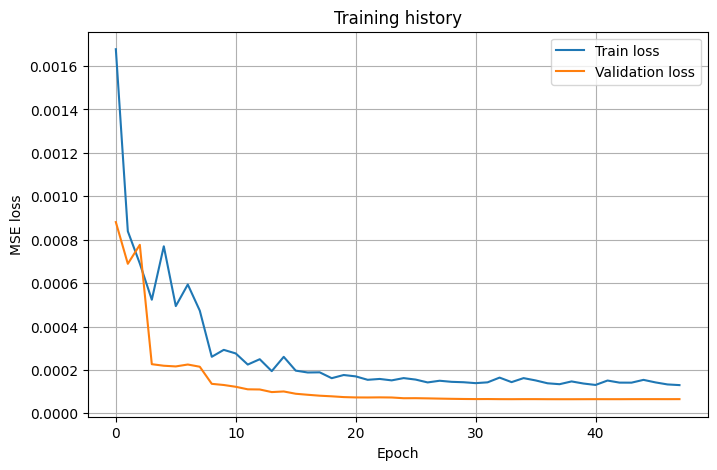

In [ ]:
# Plot training history

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Training history")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Evaluate model on the test set

test_loss, test_mae = model.evaluate(test_dataset, verbose=1)

print(f"Test loss (MSE): {test_loss:.6f}")
print(f"Test MAE:        {test_mae:.6f}")

123/123 ━━━━━━━━━━━━━━━━━━━━ 9s 76ms/step - loss: 1.5648e-05 - mae: 0.0031
Test loss (MSE): 0.000016
Test MAE:        0.003071


In [ ]:
# Generate predictions on the test set

y_pred_norm = model.predict(test_dataset).flatten()

# Collect true targets from the test dataset
y_true_norm = np.concatenate([y.numpy() for _, y in test_dataset], axis=0)

print("Number of test predictions:", len(y_pred_norm))
print("Number of true test values:", len(y_true_norm))

123/123 ━━━━━━━━━━━━━━━━━━━━ 15s 102ms/step
Number of test predictions: 3920
Number of true test values: 3920


In [ ]:
# Back-transform discharge predictions from Min-Max scaling

y_pred = y_pred_norm * (discharge_train_max - discharge_train_min) + discharge_train_min
y_true = y_true_norm * (discharge_train_max - discharge_train_min) + discharge_train_min

print("Back-transformed discharge check:")
print(f"Predicted min: {np.min(y_pred):.4f}")
print(f"Predicted max: {np.max(y_pred):.4f}")
print(f"Observed min:  {np.min(y_true):.4f}")
print(f"Observed max:  {np.max(y_true):.4f}")

Back-transformed discharge check:
Predicted min: 11.5029
Predicted max: 2373.8955
Observed min:  0.0000
Observed max:  2586.5759


In [ ]:
# Calculate evaluation metrics in original units

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae = mean_absolute_error(y_true, y_pred)
r2 = r2_score(y_true, y_pred)
nse = 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2)

print(f"Test NSE: {nse:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"Test MAE:  {mae:.4f}")
print(f"Test R2:   {r2:.4f}")

Test NSE: 0.9813
Test RMSE: 32.6647
Test MAE:  17.9335
Test R2:   0.9813


In [ ]:
# Calculate Kling-Gupta Efficiency (KGE)

r = np.corrcoef(y_true, y_pred)[0, 1]
alpha = np.std(y_pred) / np.std(y_true)
beta = np.mean(y_pred) / np.mean(y_true)

kge = 1 - np.sqrt((r - 1)**2 + (alpha - 1)**2 + (beta - 1)**2)

print(f"Test KGE: {kge:.4f}")
print(f"Correlation r: {r:.4f}")
print(f"Variability ratio alpha: {alpha:.4f}")
print(f"Bias ratio beta: {beta:.4f}")

Test KGE: 0.9201
Correlation r: 0.9926
Variability ratio alpha: 0.9314
Bias ratio beta: 1.0403


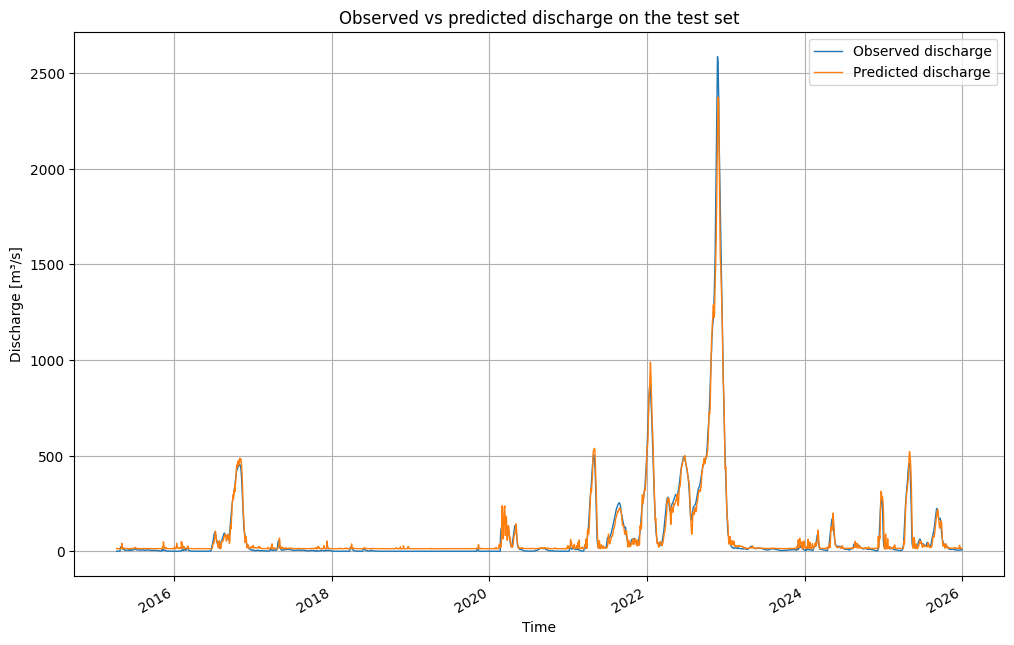

In [ ]:
# Plot observed and predicted discharge

plot_timestamps = (
    test_df["Timestamp"]
    .iloc[test_valid_idx]
    .reset_index(drop=True)
)

start_index = 0
end_index = None

plt.figure(figsize=(12, 8))

plt.plot(
    plot_timestamps[start_index:end_index],
    y_true[start_index:end_index],
    label="Observed discharge",
    linewidth=1.0
)

plt.plot(
    plot_timestamps[start_index:end_index],
    y_pred[start_index:end_index],
    label="Predicted discharge",
    linewidth=1.0
)

plt.title("Observed vs predicted discharge on the test set")
plt.xlabel("Time")
plt.ylabel("Discharge [m³/s]")
plt.legend()
plt.grid(True)
plt.gcf().autofmt_xdate()

plt.show()

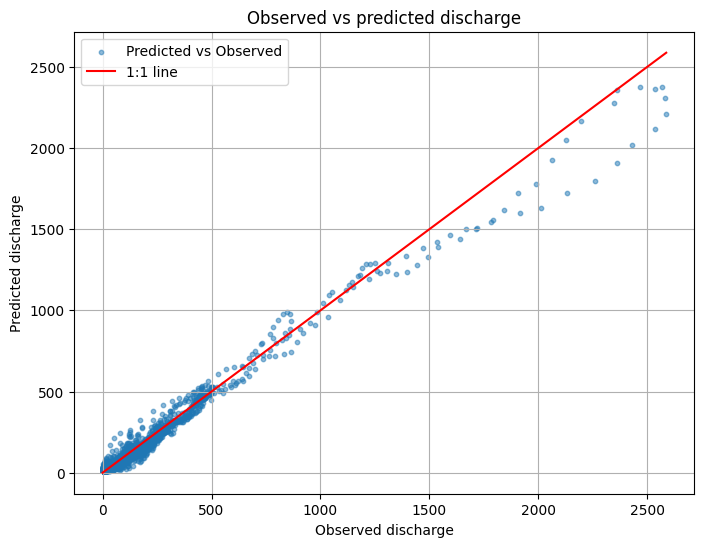

In [ ]:
# Scatter plot for observed vs predicted discharge

plt.figure(figsize=(8, 6))
plt.scatter(y_true, y_pred, alpha=0.5, s=10, label="Predicted vs Observed")

# Add 1:1 line
min_val = min(y_true.min(), y_pred.min())
max_val = max(y_true.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r', label="1:1 line")

plt.xlabel("Observed discharge")
plt.ylabel("Predicted discharge")
plt.title("Observed vs predicted discharge")
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(7, 7))

# Scatter plot
ax.scatter(
    y_true,
    y_pred,
    s=18,
    alpha=0.35,
    edgecolors="none"
)

# Common axis limits
lower = min(y_true.min(), y_pred.min())
upper = max(y_true.max(), y_pred.max())

# 1:1 reference line
ax.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--",
    linewidth=1.5,
    label="1:1 reference"
)

# Formatting
ax.set_xlim(lower, upper)
ax.set_ylim(lower, upper)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel("Observed discharge (m³ s⁻¹)")
ax.set_ylabel("Predicted discharge (m³ s⁻¹)")
ax.set_title("Observed and Predicted Discharge")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Autocorrelation values for the test period:
Lag  0: 1.0000
Lag  1: 0.9990
Lag  2: 0.9961
Lag  3: 0.9915
Lag  4: 0.9852
Lag  5: 0.9774
Lag  6: 0.9682
Lag  7: 0.9577
Lag  8: 0.9462
Lag  9: 0.9337
Lag 10: 0.9203
Lag 11: 0.9062
Lag 12: 0.8916
Lag 13: 0.8764
Lag 14: 0.8608
Lag 15: 0.8449
Lag 16: 0.8287
Lag 17: 0.8123
Lag 18: 0.7958
Lag 19: 0.7791
Lag 20: 0.7623
Lag 21: 0.7455
Lag 22: 0.7286
Lag 23: 0.7117
Lag 24: 0.6948
Lag 25: 0.6780
Lag 26: 0.6612
Lag 27: 0.6446
Lag 28: 0.6280
Lag 29: 0.6116
Lag 30: 0.5955
Lag 31: 0.5795
Lag 32: 0.5638
Lag 33: 0.5483
Lag 34: 0.5332
Lag 35: 0.5183
Lag 36: 0.5038
Lag 37: 0.4896
Lag 38: 0.4758
Lag 39: 0.4623
Lag 40: 0.4491
Lag 41: 0.4363
Lag 42: 0.4239
Lag 43: 0.4119
Lag 44: 0.4002
Lag 45: 0.3889
Lag 46: 0.3781
Lag 47: 0.3676
Lag 48: 0.3576
Lag 49: 0.3480
Lag 50: 0.3388
Lag 51: 0.3301
Lag 52: 0.3218
Lag 53: 0.3139
Lag 54: 0.3065
Lag 55: 0.2994
Lag 56: 0.2927
Lag 57: 0.2863
Lag 58: 0.2803
Lag 59: 0.2746
Lag 60: 0.2692


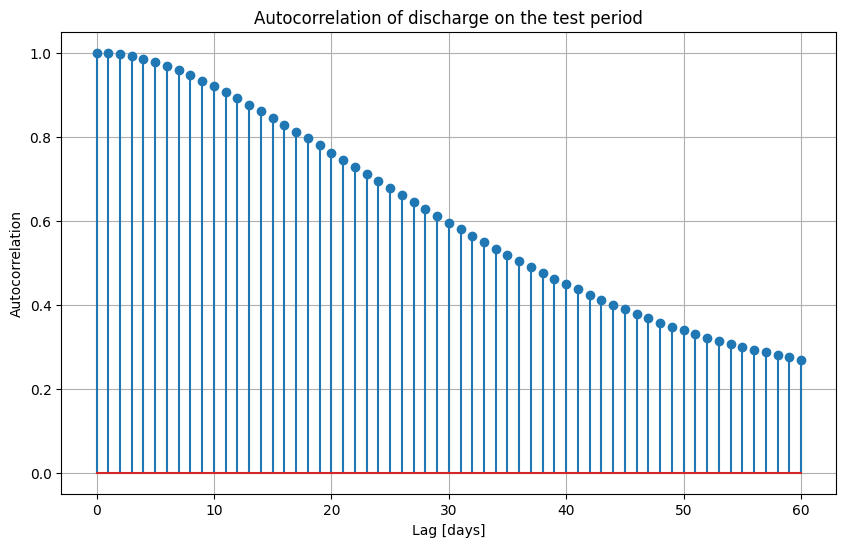

In [ ]:
# Calculate and plot discharge autocorrelation for the test period only

test_values = test_df["Value"].values.astype("float32")

max_lag = 60
acf_values_test = []

for lag in range(max_lag + 1):
    if lag == 0:
        acf = 1.0
    else:
        x1 = test_values[:-lag]
        x2 = test_values[lag:]
        acf = np.corrcoef(x1, x2)[0, 1]
    acf_values_test.append(acf)

print("Autocorrelation values for the test period:")
for lag, acf in enumerate(acf_values_test):
    print(f"Lag {lag:2d}: {acf:.4f}")

plt.figure(figsize=(10, 6))
plt.stem(range(max_lag + 1), acf_values_test)
plt.xlabel("Lag [days]")
plt.ylabel("Autocorrelation")
plt.title("Autocorrelation of discharge on the test period")
plt.grid(True)
plt.show()

In [ ]:
# Calculate persistence baseline on the test period only

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def kling_gupta_efficiency(y_true, y_pred):
    r = np.corrcoef(y_true, y_pred)[0, 1]
    alpha = np.std(y_pred) / np.std(y_true)
    beta = np.mean(y_pred) / np.mean(y_true)
    kge = 1 - np.sqrt((r - 1)**2 + (alpha - 1)**2 + (beta - 1)**2)
    return kge

test_values = test_df["Value"].values.astype("float32")

lead_times = [1, 2, 3, 4, 5, 10, 15]

print("Persistence baseline on the test period:")
print("-" * 50)

for lead_time in lead_times:
    y_true_p = test_values[lead_time:]
    y_pred_p = test_values[:-lead_time]

    rmse_p = np.sqrt(mean_squared_error(y_true_p, y_pred_p))
    mae_p = mean_absolute_error(y_true_p, y_pred_p)
    nse_p = 1 - np.sum((y_true_p - y_pred_p) ** 2) / np.sum((y_true_p - np.mean(y_true_p)) ** 2)
    kge_p = kling_gupta_efficiency(y_true_p, y_pred_p)

    print(f"Lead time {lead_time} day(s):")
    print(f"  RMSE: {rmse_p:.4f}")
    print(f"  MAE:  {mae_p:.4f}")
    print(f"  NSE:  {nse_p:.4f}")
    print(f"  KGE:  {kge_p:.4f}")

Persistence baseline on the test period:
--------------------------------------------------
Lead time 1 day(s):
  RMSE: 10.6868
  MAE:  3.6999
  NSE:  0.9980
  KGE:  0.9990
Lead time 2 day(s):
  RMSE: 20.7969
  MAE:  7.2922
  NSE:  0.9923
  KGE:  0.9961
Lead time 3 day(s):
  RMSE: 30.8041
  MAE:  10.7879
  NSE:  0.9831
  KGE:  0.9915
Lead time 4 day(s):
  RMSE: 40.6775
  MAE:  14.2067
  NSE:  0.9705
  KGE:  0.9852
Lead time 5 day(s):
  RMSE: 50.3279
  MAE:  17.5672
  NSE:  0.9548
  KGE:  0.9774
Lead time 10 day(s):
  RMSE: 94.5632
  MAE:  33.1328
  NSE:  0.8406
  KGE:  0.9203
Lead time 15 day(s):
  RMSE: 131.9836
  MAE:  46.6689
  NSE:  0.6898
  KGE:  0.8449


In [ ]:
# Analyze prediction error by discharge range

results_df = pd.DataFrame({
    "y_true": y_true,
    "y_pred": y_pred
})

results_df["error"] = results_df["y_pred"] - results_df["y_true"]
results_df["abs_error"] = np.abs(results_df["error"])

# Create bins based on observed discharge quantiles
results_df["flow_bin"] = pd.qcut(results_df["y_true"], q=5, duplicates="drop")

error_summary = results_df.groupby("flow_bin").agg(
    mean_true=("y_true", "mean"),
    mean_pred=("y_pred", "mean"),
    mean_error=("error", "mean"),
    mean_abs_error=("abs_error", "mean"),
    count=("y_true", "size")
)

print(error_summary)

                     mean_true   mean_pred  mean_error  mean_abs_error  count
flow_bin                                                                     
(-0.001, 0.0838]      0.000929   13.999769   13.998840       13.998840    784
(0.0838, 5.577]       2.747339   15.055372   12.308033       12.308033    787
(5.577, 14.394]       9.038244   17.073275    8.035030        8.037428    781
(14.394, 79.292]     32.974335   32.563370   -0.410964       12.157092    784
(79.292, 2586.576]  383.226929  366.531006  -16.695898       43.149529    784


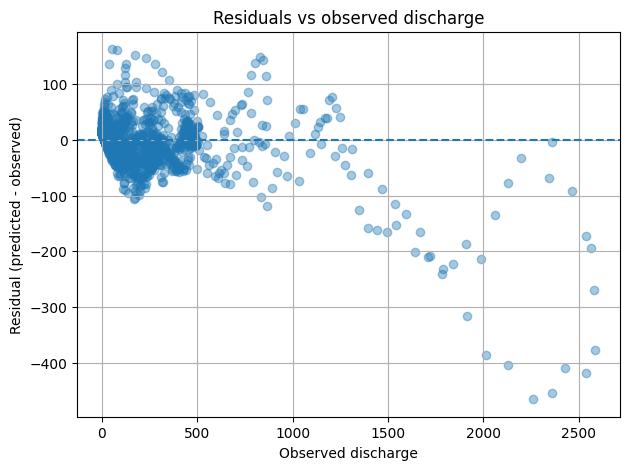

In [ ]:
# Plot residuals against observed discharge

import matplotlib.pyplot as plt

residuals = y_pred - y_true

plt.figure(figsize=(7, 5))
plt.scatter(y_true, residuals, alpha=0.4)
plt.axhline(0, linestyle="--")
plt.xlabel("Observed discharge")
plt.ylabel("Residual (predicted - observed)")
plt.title("Residuals vs observed discharge")
plt.grid(True)
plt.show()

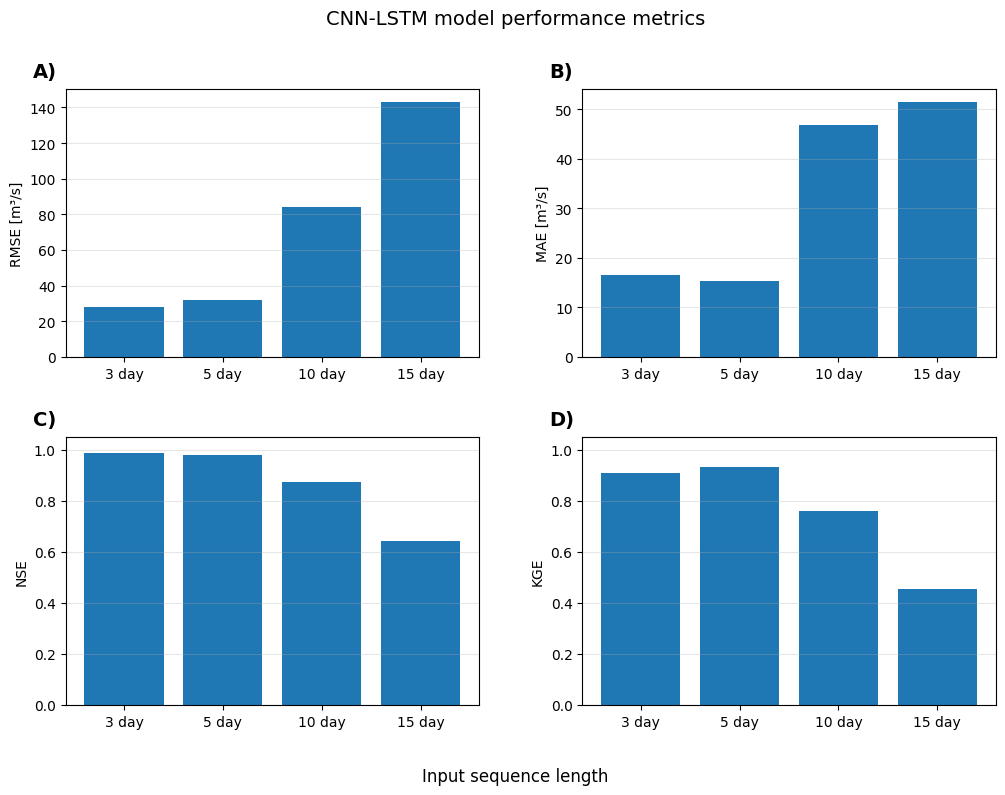

In [ ]:
# Plot performance metrics for one model across forecast horizons

# 1) Define forecast horizons and metric values

horizons = ["3 day", "5 day", "10 day", "15 day"]
x = np.arange(len(horizons))

rmse = [28.08, 31.82, 83.91, 143.22]
mae = [16.63, 15.26, 46.78, 51.54]
nse = [0.986, 0.982, 0.876, 0.641]
kge = [0.910, 0.935, 0.760, 0.455]

# 2) Create 2x2 subplot figure

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.subplots_adjust(hspace=0.3, wspace=0.25)

# 3) RMSE plot

axes[0, 0].bar(x, rmse)
axes[0, 0].set_ylabel("RMSE [m³/s]")
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(horizons)
axes[0, 0].grid(True, axis="y", alpha=0.3)
axes[0, 0].text(-0.08, 1.10, "A)", transform=axes[0, 0].transAxes,
                ha="left", va="top", fontsize=14, fontweight="bold")

# 4) MAE plot

axes[0, 1].bar(x, mae)
axes[0, 1].set_ylabel("MAE [m³/s]")
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(horizons)
axes[0, 1].grid(True, axis="y", alpha=0.3)
axes[0, 1].text(-0.08, 1.10, "B)", transform=axes[0, 1].transAxes,
                ha="left", va="top", fontsize=14, fontweight="bold")

# 5) NSE plot

axes[1, 0].bar(x, nse)
axes[1, 0].set_ylabel("NSE")
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(horizons)
axes[1, 0].set_ylim(0, 1.05)
axes[1, 0].grid(True, axis="y", alpha=0.3)
axes[1, 0].text(-0.08, 1.10, "C)", transform=axes[1, 0].transAxes,
                ha="left", va="top", fontsize=14, fontweight="bold")

# 6) KGE plot

axes[1, 1].bar(x, kge)
axes[1, 1].set_ylabel("KGE")
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(horizons)
axes[1, 1].set_ylim(0, 1.05)
axes[1, 1].grid(True, axis="y", alpha=0.3)
axes[1, 1].text(-0.08, 1.10, "D)", transform=axes[1, 1].transAxes,
                ha="left", va="top", fontsize=14, fontweight="bold")

# 7) Add common x-axis label and overall title

fig.supxlabel("Input sequence length")
fig.suptitle("CNN-LSTM model performance metrics", fontsize=14)

plt.show()